<small>Dataset: Student_Performance.csv</small>

# Q31. Student Pass Fail ANN

Build and train a small feed-forward binary classification neural network.


## Question from Classroom

Student Pass/Fail Prediction Using ANN 
Problem statement: Build an Artificial Neural Network to predict whether a student will pass 
or fail based on academic attributes. 
Tasks to be performed: 
1. Load a labeled student performance dataset with a pass/fail target. 
2. Select suitable input features and encode categorical data where necessary. 
3. Split the data into training and testing sets. 
4. Normalize numerical features using training-set statistics. 
5. Create and train a feed-forward neural network for binary classification. 
6. Predict test-set labels and display accuracy, precision, recall and a confusion matrix.


## Understand before coding

Read X/y -> fit/validation/test split -> one-hot encode -> training-only imputation and scaling -> build -> compile -> train -> threshold probabilities -> evaluate.


**Dataset / practice note:** This file has no pass/fail labels; the 50-point threshold is clearly marked as a practice assumption.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl tensorflow
```


**Code layout:** 6 listed tasks → 6 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a labeled student performance dataset with a pass/fail target.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

import tensorflow as tf
from sklearn.preprocessing import StandardScaler
tf.keras.utils.set_random_seed(42)

df=pd.read_csv("data/Student_Performance.csv").dropna(subset=["Performance Index"])
# The original file has no pass/fail target; this is a clearly labeled practice rule.
y=(df["Performance Index"]>=50).astype(int)
print("Practice pass rule: Performance Index >= 50")


Practice pass rule: Performance Index >= 50


## Task 2. Select suitable input features and encode categorical data where necessary.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
X=df.drop(columns="Performance Index").copy()
X["Extracurricular Activities"]=X["Extracurricular Activities"].map({"Yes":1,"No":0})
print("Predictor columns:",X.columns.tolist())
print("Yes/No activity encoded using a fixed mapping; the target source is excluded.")


Predictor columns: ['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced']
Yes/No activity encoded using a fixed mapping; the target source is excluded.


## Task 3. Split the data into training and testing sets.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_fit,X_valid,y_fit,y_valid=train_test_split(X_train,y_train,test_size=0.2,random_state=42,stratify=y_train)


## Task 4. Normalize numerical features using training-set statistics.

This block implements the task above. Variables from earlier blocks are reused.


In [4]:
# Learn category columns from fitting rows; align validation and test to them.
X_fit = pd.get_dummies(X_fit,dtype=int)
X_valid = pd.get_dummies(X_valid,dtype=int).reindex(columns=X_fit.columns,fill_value=0)
X_test = pd.get_dummies(X_test,dtype=int).reindex(columns=X_fit.columns,fill_value=0)
medians = X_fit.median()
X_fit = X_fit.fillna(medians)
X_valid = X_valid.fillna(medians)
X_test = X_test.fillna(medians)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(X_fit).astype("float32")
valid_scaled = scaler.transform(X_valid).astype("float32")
test_scaled = scaler.transform(X_test).astype("float32")
print("Fit rows:",len(X_fit),"Validation rows:",len(X_valid),"Test rows:",len(X_test))
print("Encoded input features:",X_fit.shape[1])


Fit rows: 6400 Validation rows: 1600 Test rows: 2000
Encoded input features: 5


## Task 5. Create and train a feed-forward neural network for binary classification.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(train_scaled.shape[1],)),
    tf.keras.layers.Dense(16,activation="relu"),
    tf.keras.layers.Dense(8,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid")
])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
model.summary()
history = model.fit(train_scaled,y_fit,epochs=15,batch_size=32,
                    validation_data=(valid_scaled,y_valid),verbose=0)
print("Training completed: 15 epochs")


Model: "sequential_1"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 241 (964.00 B)
 Trainable params: 241 (964.00 B)
 Non-trainable params: 0 (0.00 B)
Training completed: 15 epochs


## Task 6. Predict test-set labels and display accuracy, precision, recall and a confusion matrix.

This block implements the task above. Variables from earlier blocks are reused.


Accuracy: 0.972
Confusion matrix:
 [[ 780   38]
 [  18 1164]]
              precision    recall  f1-score   support

           0       0.98      0.95      0.97       818
           1       0.97      0.98      0.98      1182

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000

   Actual  Probability of class 1  Predicted
0       1                0.999992          1
1       1                0.999784          1
2       0                0.000072          0
3       0                0.024621          0
4       1                0.999982          1
5       0                0.014070          0
6       1                0.999997          1
7       1                0.999926          1
8       1                0.999993          1
9       0                0.000356          0


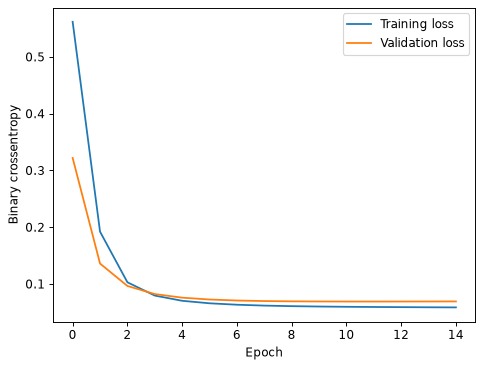

In [6]:
probability = model.predict(test_scaled,verbose=0).ravel()
prediction = (probability >= 0.5).astype(int)
print("Accuracy:",round(accuracy_score(y_test,prediction),4))
print("Confusion matrix:\n",confusion_matrix(y_test,prediction,labels=[0,1]))
print(classification_report(y_test,prediction,zero_division=0))
print(pd.DataFrame({"Actual":np.asarray(y_test),"Probability of class 1":probability,
                    "Predicted":prediction}).head(10))
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary crossentropy"); plt.legend(); plt.show()


## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. What is an ANN?**

A network of units applying weighted sums, biases and nonlinear activation functions to learn a mapping from inputs to outputs.

**14. Describe the architecture here.**

The input width equals the encoded feature count, followed by Dense layers with 16 ReLU units, 8 ReLU units and one sigmoid output unit.

**15. Why ReLU?**

ReLU(x)=max(0,x). It introduces nonlinearity so multiple layers can model more than a single linear transformation.

**16. Why one sigmoid output?**

sigmoid(z)=1/(1+exp(-z)) gives a value between 0 and 1 for binary class 1. The default decision threshold is 0.5.

**17. Why binary crossentropy?**

For a binary target it penalizes incorrect probability estimates: -[y*log(p)+(1-y)*log(1-p)], averaged over examples.

**18. What does Adam do?**

It is a gradient-based optimizer with adaptive per-parameter update scaling and momentum-like estimates.

**19. What is an epoch and batch?**

An epoch is one complete pass through training examples. A batch is the group used for one gradient update; here batch_size=32.

**20. What is backpropagation?**

Using the chain rule to calculate loss gradients through network layers so the optimizer can update weights.

**21. Why separate fitting, validation and test sets?**

Fit weights on fitting rows, monitor learning on validation rows, and reserve the test split for final evaluation. Scaling and category layout are learned from fitting rows only.

**22. How can overfitting appear?**

Training loss decreases while validation loss worsens. Possible controls include fewer epochs, a smaller network, regularization, dropout or early stopping.

**23. Does the model guarantee a useful classifier?**

No. Compare the actual per-class results against a simple baseline, especially for imbalanced labels. A majority-class prediction can have deceptively high accuracy.

**24. Complexity?**

Work is roughly proportional to epochs times training examples times the number of weights, with architecture and implementation affecting runtime.

**25. Where does pass/fail come from?**

The attached file has no pass/fail column. The practice definition is Performance Index >=50. It is not an official grading rule.

**26. Why remove Performance Index?**

It is used to construct the label. Keeping it in X would expose the answer and invalidate the learning exercise.


### Task-to-code map

- **Block 1:** Load a labeled student performance dataset with a pass/fail target.
- **Block 2:** Select suitable input features and encode categorical data where necessary.
- **Block 3:** Split the data into training and testing sets.
- **Block 4:** Normalize numerical features using training-set statistics.
- **Block 5:** Create and train a feed-forward neural network for binary classification.
- **Block 6:** Predict test-set labels and display accuracy, precision, recall and a confusion matrix.
